# Оценка числа полей в совокупности от числа выведенных блоков

In [1]:
import sys
import os
import json

sys.path.append('./../')

In [2]:
import pandas as pd
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
QUERIES_CNT = 16
RUNS = 8

## Вспомогательные функции

In [4]:
def count_fields(df: pd.DataFrame, q_id: int, run_id: int):
    loc_df = df.loc[(df['query_id'] == q_id) & (df['run_id'] == run_id)]
    fields_cnt = len(loc_df)
    return fields_cnt

def count_tables_34(df: pd.DataFrame, q_id: int, run_id: int):
    loc_df = df.loc[(df['query_id'] == q_id) & (df['run_id'] == run_id)]
    nodes_set = set()
        
    for r_id, row in loc_df.iterrows():
        node_name = row['node_name']
        nodes_set.add(node_name)
    return len(nodes_set)

def count_tables_2(df: pd.DataFrame, q_id: int, run_id: int):
    loc_df = df.loc[(df['query_id'] == q_id) & (df['run_id'] == run_id)]
    nodes_set = set()
        
    for r_id, row in loc_df.iterrows():
        row_nodes = row['dag_step']
        row_nodes = set(row_nodes)
        nodes_set = nodes_set.union(row_nodes)

    return len(nodes_set)


## Функции визуализации

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D

def _task_colors(n):
    cmap = cm.get_cmap("tab20", n)
    return [cmap(i) for i in range(n)]
 
 
def plot_fields_vs_tables(
    tables,
    fields,
    pipeline_labels=None,
    task_ids=None,
    show_colors=False,
    show_means=False,
    save_path=None,
    show=True,
):
    
    plt.rcParams.update({
        "font.family":      "serif",
        "font.serif":       ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
    })

    tables = np.asarray(tables, dtype=float)   # (3, 16, 8)
    fields = np.asarray(fields, dtype=float)   # (3, 16, 8)
 
    n_pipelines, n_tasks, n_runs = tables.shape
    assert fields.shape == tables.shape, "tables and fields must have the same shape"
 
    if pipeline_labels is None:
        pipeline_labels = [f"Pipeline {chr(65 + i)}" for i in range(n_pipelines)]
    if task_ids is None:
        task_ids = [f"Task {i+1}" for i in range(n_tasks)]
 
    colors = _task_colors(n_tasks) if show_colors else ["#555555"] * n_tasks
 
    fig, axes = plt.subplots(1, n_pipelines, figsize=(6 * n_pipelines, 5.5))
    if n_pipelines == 1:
        axes = [axes]
 
    for p_idx, ax in enumerate(axes):
        t_pipe = tables[p_idx]   # (16, 8)
        f_pipe = fields[p_idx]   # (16, 8)
 
        # ── scatter ───────────────────────────────────────────────────────────
        for t_idx in range(n_tasks):
            ax.scatter(
                t_pipe[t_idx], f_pipe[t_idx],
                color=colors[t_idx],
                edgecolors="white", linewidths=0.4,
                s=55, alpha=0.75, zorder=3,
            )
 
        # ── per-task mean diamonds (optional) ─────────────────────────────────
        if show_means:
            for t_idx in range(n_tasks):
                ax.scatter(
                    t_pipe[t_idx].mean(), f_pipe[t_idx].mean(),
                    color=colors[t_idx],
                    edgecolors="black", linewidths=1.2,
                    s=140, marker="D", zorder=5,
                )
 
        # ── adaptive limits ───────────────────────────────────────────────────
        x, y = t_pipe.ravel(), f_pipe.ravel()
        x_pad = (x.max() - x.min()) * 0.07 or 1
        y_pad = (y.max() - y.min()) * 0.07 or 1
        xlim = (x.min() - x_pad, x.max() + x_pad)
        ylim = (y.min() - y_pad, y.max() + y_pad)
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
 
        # ── OLS trend line ────────────────────────────────────────────────────
        if x.std() > 0:
            coeffs = np.polyfit(x, y, 1)
            x_line = np.linspace(xlim[0], xlim[1], 200)
            ax.plot(x_line, np.polyval(coeffs, x_line),
                    color="black", lw=1.8, ls="--", zorder=4)
            slope, intercept = coeffs
            r = np.corrcoef(x, y)[0, 1]
            ax.text(
                0.97, 0.04,
                f"y = {slope:.2f}x + {intercept:.1f}\nr = {r:.2f}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=16,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="grey", alpha=0.7),
            )
 
        # ── styling ───────────────────────────────────────────────────────────
        ax.set_title(pipeline_labels[p_idx], fontsize=20, pad=10)
        ax.set_xlabel("Nodes count", fontsize=18)
        ax.set_ylabel("Fields count", fontsize=18)
        ax.tick_params(axis="both", labelsize=14)
        ax.grid(True, linestyle="--", alpha=0.45, zorder=0)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
 
    # ── legend ────────────────────────────────────────────────────────────────
    legend_handles = []
 
    if show_colors:
        legend_handles += [
            Line2D([0], [0], marker="o", color="w",
                   markerfacecolor=colors[i], markeredgecolor="white",
                   markersize=8, label=task_ids[i])
            for i in range(n_tasks)
        ]
 
    if show_means:
        legend_handles.append(
            Line2D([0], [0], marker="D", color="w",
                   markerfacecolor="grey", markeredgecolor="black",
                   markersize=9, label="Task mean")
        )
 
    legend_handles.append(
        Line2D([0], [0], color="black", lw=1.8, ls="--", label="OLS trend")
    )
 
    # fig.legend(
    #     handles=legend_handles,
    #     loc="lower center",
    #     ncol=min(len(legend_handles), 6),
    #     fontsize=18,
    #     frameon=False,
    #     bbox_to_anchor=(0.5, -0.25),
    # )
 
    # fig.suptitle(
    #     "Total number of fields from the number of data processing stages",
    #     fontsize=24, y=1.02,
    # )
    plt.tight_layout()
 
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved → {save_path}")
 
    if show:
        plt.show()
 
    return fig, axes


# Визуализация результатов

In [27]:
md_tables = {
    'Single Call (with DAG reasoning)': './../data/openai/md_generations/m2_synth_bio_mds.csv',
    'Using unregularized DAG': './../data/openai/md_generations/m3_synth_bio_mds/m3_synth_bio_mds.csv',
    'Using regularized DAG': './../data/openai/md_generations/m4_synth_bio_mds/m4_synth_bio_mds.csv',
}

nodes_counter = {
    'Single Call (with DAG reasoning)': count_tables_2,
    'Using unregularized DAG': count_tables_34,
    'Using regularized DAG': count_tables_34,
}

tables = []
fields = []

for p_name, p_path in md_tables.items():
    df = pd.read_csv(p_path)

    schemas_tables = []
    schemas_fields = []

    for q_id in range(QUERIES_CNT):
        q_tables = []
        q_fields = []
        
        for run in range(RUNS):
            fields_cnts = count_fields(df, q_id, run)
            tables_cnts = nodes_counter[p_name](df, q_id, run)
            
            q_fields.append(fields_cnts)
            q_tables.append(tables_cnts)
    
        schemas_tables.append(q_tables)
        schemas_fields.append(q_fields)

    tables.append(schemas_tables)
    fields.append(schemas_fields)

## Визуализация

In [28]:
import json

task_labels = []
with open('./../queries/bio_queries.yaml', 'rt') as fio:
    d = json.load(fio)
    for el in d:
        task_labels.append(el['field_of_science'].split('/')[-1].strip())
task_labels

['Single-Cell Genomics',
 'Microbial Ecology',
 'Behavioral Neurobiology',
 'Plankton Ecology',
 'Infectious Disease Genomics',
 'Rhizosphere Ecology',
 'Molecular Gerontology',
 'Pollination Biology',
 'Mitochondrial Physiology',
 'Clinical Metagenomics',
 'Systems Neuroscience',
 'Ichthyology',
 'Molecular Biophysics',
 'Carbon Metabolism',
 'Cell Invasion Biology',
 'Cell Biology']

/tmp/ipykernel_6336/4152656375.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab20", n)


Saved → ./paper_img.png


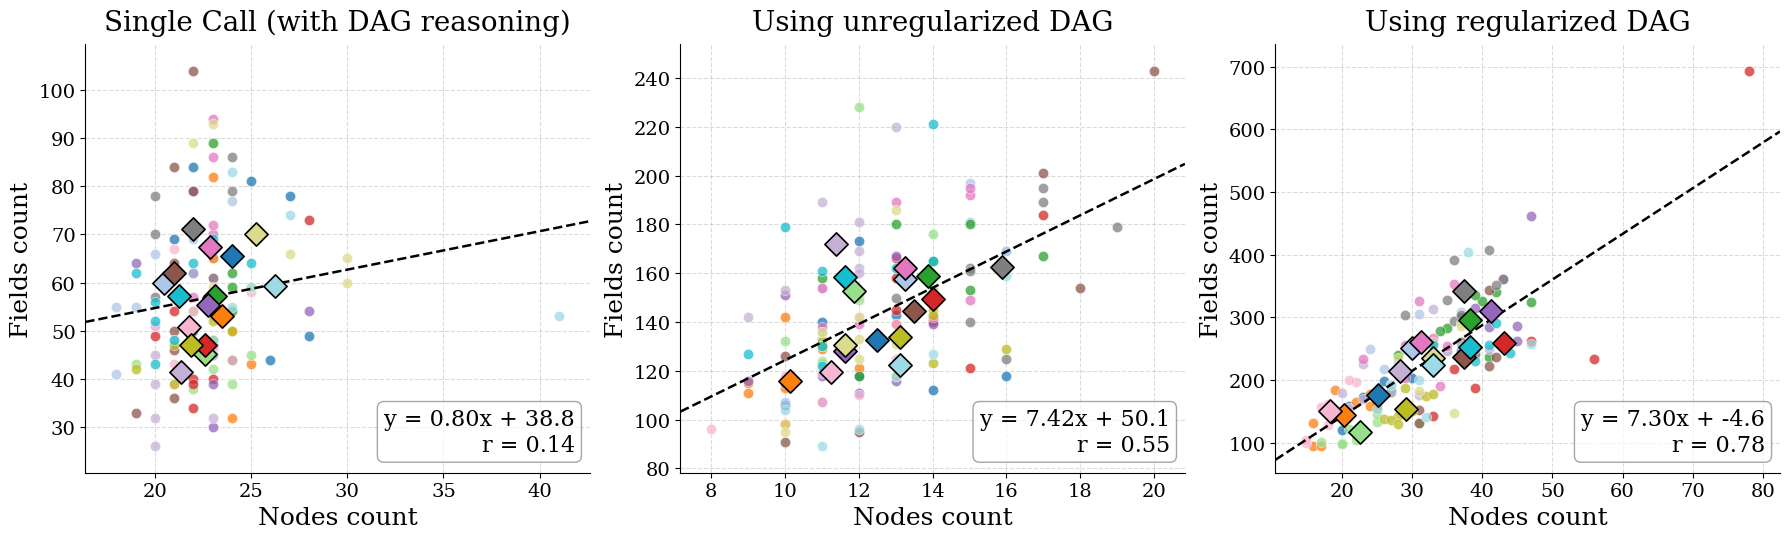

(<Figure size 1800x550 with 3 Axes>,
 array([<Axes: title={'center': 'Single Call (with DAG reasoning)'}, xlabel='Nodes count', ylabel='Fields count'>,
        <Axes: title={'center': 'Using unregularized DAG'}, xlabel='Nodes count', ylabel='Fields count'>,
        <Axes: title={'center': 'Using regularized DAG'}, xlabel='Nodes count', ylabel='Fields count'>],
       dtype=object))

In [29]:
plot_fields_vs_tables(
    tables,
    fields,
    #task_ids=task_labels,
    pipeline_labels=list(md_tables.keys()),
    save_path="./paper_img.png",
    show=True,
    show_colors=True,
    show_means=True
)
